# Scientific Python: NumPy, SciPy and Matplotlib

Open this notebook in the module's `mpm2026` environment, which has everything the cells below need.

## Today's Learning objectives

  * Learn what NumPy arrays are
  * Learn basic array manipulations
  * Learn what vectorised code is
  * Quick overview of SciPy
  * Learn how to create a simple 2D plot and decorate it
  * Learn how to combine multiple plots into a single figure

Some aspects of today's lecture will be revision for many of you. However, we'll mention some important concepts that you may not have thought about previously, e.g. the importance of utilising `NumPy` vectorisation in writing efficient code! Understanding and appreciating these finer aspects of using `NumPy` will be crucial going forward in this course.

## Further reading
* https://lectures.scientific-python.org (formerly scipy-lectures.org)
* https://www.nature.com/articles/s41586-020-2649-2
* https://numpy.org/doc/

## The scientific Python ecosystem

The packages in this lecture are part of what is often called the *scientific Python ecosystem*: open-source packages for mathematics, science and engineering that build on one another. Some of the core ones are:
  * NumPy
  * SciPy
  * Matplotlib
  * IPython
  * SymPy
  * pandas

...and many more (see [scientific-python.org](https://scientific-python.org)). "SciPy" was once the name for this whole collection; today it means the library of that name, "fundamental algorithms for scientific computing in Python" ([scipy.org](https://scipy.org)).

## NumPy

* NumPy is a key building block used by SciPy.

* NumPy supports:

  * Multidimensional arrays (`ndarray`)
  * Matrices and linear algebra operations
  * Random number generation
  * Fourier transforms
  * Polynomials
  * Tools for integrating with Fortran/C libraries
  
* NumPy provides fast precompiled functions for numerical routines.

* Official website: https://www.numpy.org/

## "Array programming with NumPy"
https://www.nature.com/articles/s41586-020-2649-2

**Abstract**: *Array programming provides a powerful, compact and expressive syntax for accessing, manipulating and operating on data in vectors, matrices and higher-dimensional arrays. NumPy is the primary array programming library for the Python language. It has an essential role in research analysis pipelines in fields as diverse as physics, chemistry, astronomy, geoscience, biology, psychology, materials science, engineering, finance and economics. For example, in astronomy, NumPy was an important part of the software stack used in the discovery of gravitational waves and in the first imaging of a black hole. Here we review how a few fundamental array concepts lead to a simple and powerful programming paradigm for organizing, exploring and analysing scientific data. NumPy is the foundation upon which the scientific Python ecosystem is constructed. It is so pervasive that several projects, targeting audiences with specialized needs, have developed their own NumPy-like interfaces and array objects. Owing to its central position in the ecosystem, NumPy increasingly acts as an interoperability layer between such array computation libraries and, together with its application programming interface (API), provides a flexible framework to support the next decade of scientific and industrial analysis.*

### NumPy Arrays overview

* Core (or Standard) Python Library provides lists and 1D arrays

  * Lists are general containers for objects
  * Arrays are 1D containers for objects of the same type
  * Limited functionality
  * Some memory and performance overhead associated with these structures

* NumPy provides multidimensional arrays (`numpy.ndarray`)
  * Can store many elements of the same data type in multiple dimensions
  * cf. Fortran/C/C++ arrays
  * More functionality than Core Python e.g. many convenient methods for array manipulation
  * Efficient storage and execution

* [Extensive online documentation](https://numpy.org/doc/stable/)

### Interactive figures

Later in this lecture we use `%matplotlib widget` to make figures interactive (zoom, pan, sliders). This needs the `ipympl` package, which is part of the module's `mpm2026` environment, so there is nothing to install.

#### Some required imports

In [1]:
# Convention: Import numpy and alias/rename it as np
import numpy as np

### Creating 1D arrays

There are many ways to create 1d array, *e.g.*:

In [2]:
# Create array from Python list.
a = np.array([-1, 0, 1])
print(a)

[-1  0  1]


In [3]:
# Create array using the array class copy constructor.
b = np.array(a)
print(b)

[-1  0  1]


While these might look the same when printed above, all `NumPy` arrays are of type '`ndarray`':

In [4]:
print(type(b))
li = [1, 2, 3]
print(type(li))

<class 'numpy.ndarray'>
<class 'list'>


Arrays can also be created using `NumPy` functions, *e.g.*

In [5]:
# https://numpy.org/doc/stable/reference/generated/numpy.arange.html
# arange for arrays (like using range for lists)
a = np.arange(-2, 6, 2)
print(a)

[-2  0  2  4]


In [6]:
# https://numpy.org/doc/stable/reference/generated/numpy.linspace.html
# linspace to create sample step points in an interval
a = np.linspace(-10, 10, 4) 
print(a)

[-10.          -3.33333333   3.33333333  10.        ]


In [7]:
# Contrast this with arange.
print(np.arange(-10, 10, 4))

[-10  -6  -2   2   6]


### <span style="color:blue">Exercise 2.1</span>
Add comments explaining what the following `NumPy` functions do.

In [8]:
b = np.zeros(3)
print(b)

[0. 0. 0.]


In [9]:
c = np.ones(3)
print(c)

[1. 1. 1.]


In [10]:
d = np.eye(3)
print(d)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### Array attributes

As part of the array structure, `NumPy` keeps track of metadata for the array as "attributes".

In [11]:
# Taking "a" from the previous example
a = np.linspace(-10, 10, 5) 

In [12]:
# Examine key array attributes
print(a)
print("Dimensions ", a.ndim)   # Number of dimensions
print("Shape      ", a.shape)  # number of elements in each dimension
print("Size       ", a.size)   # total number of elements
print("Data type  ", a.dtype)  # data type of element, 64 bit float (IEEE 754) by default

[-10.  -5.   0.   5.  10.]
Dimensions  1
Shape       (5,)
Size        5
Data type   float64


Basic data type can be specified at creation:

In [13]:
a = np.array( [1.1,2.2,3.3], np.float32)
print(a)
print("Data type", a.dtype)

[1.1 2.2 3.3]
Data type float32


In [14]:
a = np.array([1,2,3,4], np.float64)
print(a)
print("Data type", a.dtype)

[1. 2. 3. 4.]
Data type float64


### Multi-dimensional arrays

There are many different ways to create N-dimensional arrays. A two-dimensional array or matrix can be created from, e.g., list of lists.

In [15]:
mat = np.array( [[1,2,3], [4,5,6]] )
print(mat)
print("Dimensions: ", mat.ndim)
print("Size:       ", mat.size)
print("Shape:      ", mat.shape)

[[1 2 3]
 [4 5 6]]
Dimensions:  2
Size:        6
Shape:       (2, 3)


`pprint` (*'pretty print'*) displays an array the way it appears when it is the last line of a cell (its `repr`, e.g. `array([[1, 2, 3], ...])`), which is handy for showing several arrays from one cell:

In [16]:
from pprint import pprint

pprint(mat)

array([[1, 2, 3],
       [4, 5, 6]])


You can create 2d arrays with complex elements by specifying the data type.

In [17]:
alist = [[1, 2, 3], [4, 5, 6]]
mat = np.array(alist, complex)
pprint(mat)

array([[1.+0.j, 2.+0.j, 3.+0.j],
       [4.+0.j, 5.+0.j, 6.+0.j]])


### <span style="color:blue">Exercise 2.2</span>

Work out the shape of the resulting arrays by 'sight'. <br>

In [18]:
## don't change the following line of code in any way
a = np.array([[11, 12, 13], [21, 22, 23], [31, 32, 33], [41, 42, 43]])
b = np.array([[[1, 1], [2, 2], [3, 3], [4, 4]], [[1, 1], [2, 2], [3, 3], [4, 4]],
              [[1, 1], [2, 2], [3, 3], [4, 4]]])

Now, write their shapes as `tuple`s in the cell below:

In [19]:
## Solution
shape_a = a.shape
shape_b = b.shape

In [20]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert shape_a == a.shape, "shape_a is not quite right: count the rows, then the entries in each row"
assert shape_b == b.shape, "shape_b is not quite right: count the brackets from the outside in"
print("Both shapes are correct.")

Both shapes are correct.


In [21]:
pprint(a)
print("a", a.shape)
print(a.ndim)
print(a.size)

array([[11, 12, 13],
       [21, 22, 23],
       [31, 32, 33],
       [41, 42, 43]])
a (4, 3)
2
12


In [22]:
pprint(b)
print("b", b.shape)
print(b.ndim)
print(b.size)

array([[[1, 1],
        [2, 2],
        [3, 3],
        [4, 4]],

       [[1, 1],
        [2, 2],
        [3, 3],
        [4, 4]],

       [[1, 1],
        [2, 2],
        [3, 3],
        [4, 4]]])
b (3, 4, 2)
3
24


### Accessing arrays

Basic indexing and slicing can be used to access array elements, as we know from lists.

In [23]:
# a[start:stop:stride] (not inclusive of stop)
a = np.arange(8)     # another function for creating arrays
print("a", a)
print("a[2:4]", a[2:4])
print("a[0:7:3]", a[0:7:3])
print("a[:5:2]", a[:5:2])

a [0 1 2 3 4 5 6 7]
a[2:4] [2 3]
a[0:7:3] [0 3 6]
a[:5:2] [0 2 4]


Negative (or modulo) indices are valid:

In [24]:
# To, e.g., access the last element
print(a[-1])

7


### <span style="color:blue">Exercise 2.3</span>

Manually create an `np.array` called `b` which is equivalent to the output of `a[2:-3:2]`.

In [25]:
## Solution
b = np.array(a[2:-3:2])

In [26]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert isinstance(b, np.ndarray), "b should be a NumPy array"
assert np.array_equal(b, a[2:-3:2]), "b is not the same as a[2:-3:2]"
print("Correct.")

Correct.


For multi-dimensional arrays, tuples or index notations can be used.

In [27]:
# Basic indexing of a 3d array
c = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])
pprint(c)

array([[[1, 2],
        [3, 4]],

       [[5, 6],
        [7, 8]]])


In [28]:
print(c.shape)
print("c[1][0][1]:", c[1][0][1]) # using index notation
print("c[1, 0, 1]:", c[1, 0, 1]) # using a tuple (more performant)

(2, 2, 2)
c[1][0][1]: 6
c[1, 0, 1]: 6


In [29]:
c = np.array([[1, 2, 3],[5, 6, 8]])
pprint(c)
print(c.shape)
print("c[1][2]:", c[1][2]) # using index notation
print("c[1, 2]:", c[1, 2])     # using a tuple (more performant)

array([[1, 2, 3],
       [5, 6, 8]])
(2, 3)
c[1][2]: 8
c[1, 2]: 8


In [30]:
c = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])
pprint(c)

array([[[1, 2],
        [3, 4]],

       [[5, 6],
        [7, 8]]])


If the number of indices given is less than the number of axes, missing axes are taken as complete slices.

In [31]:
pprint(c[1])
pprint(c[1, 0])
pprint(c[1, 0, ...]) # can use ellipsis (3 dots) for missing indices

array([[5, 6],
       [7, 8]])
array([5, 6])
array([5, 6])


Slice objects can also be created to extract/manipulate indices. A slice object takes the form `slice(start, stop, step)`. Therefore, to take the slice `a[2:-3:2]` we could also write

In [32]:
pprint(a)
pprint(a[2:-3:2])
my_slice = (slice(2, -3, 2))
pprint(a[my_slice])

array([0, 1, 2, 3, 4, 5, 6, 7])
array([2, 4])
array([2, 4])


Note that a negative step can also be used to reverse an array. Take for example

In [33]:
d = np.arange(9).reshape(3,3)
print(d)

[[0 1 2]
 [3 4 5]
 [6 7 8]]


This can be reversed along both axes via

In [34]:
print(d[::-1, ::-1])

[[8 7 6]
 [5 4 3]
 [2 1 0]]


or equivalently

In [35]:
print(d[(slice(None, None, -1), slice(None, None, -1))])

[[8 7 6]
 [5 4 3]
 [2 1 0]]


### Array copies

Simple assignment does not copy an array: it gives the same array a second name (a reference).

In [36]:
a = np.array([-2, 6, 2])
print("a", a)
b = a
a[0] = 20

# b points to a, hence printing a and b will produce the same result
pprint(a)
pprint(b)

a [-2  6  2]
array([20,  6,  2])
array([20,  6,  2])


Use `copy()` to create an independent copy, with its own data.

In [37]:
c = a.copy()
# check c really is an independent copy of a
c[2] = 42
print(a)
print(c)

[20  6  2]
[20  6 42]


### Views from slices

A "view" is an array that refers to another array's data (like references). You can create a view of an array by selecting a slice of an array. No data is copied when a view is created.

In [38]:
a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]]) 
pprint(a)

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])


In [39]:
# You then create a view as follows:
s = a[2:3, 1:3]
print(s)

[[8 9]]


Let's check what happens to `a` if we modify the elements of `s`:

In [40]:
s[:, :] = -2
print("s", s)
print("a", a)

s [[-2 -2]]
a [[ 1  2  3]
 [ 4  5  6]
 [ 7 -2 -2]]


### <span style="color:blue">Exercise 2.4</span>
Create a two-dimensional array called `m` to represent the following matrix,
$$
\mathbf{m} = \left\lbrack\begin{array}{ccc}
1 & 1 & 2\cr
3 & 5 & 8\cr
13 & 21 & 34\cr
55 & 89 & 144
\end{array}\right\rbrack
$$

Then change all the elements with values 21, 34, 89, and 144 in matrix `m` (i.e. bottom right corner elements) to 1001 by using a slice.

In [42]:
## Solution

m = np.array([[1,1,2],[3,5,8],[13,21,34],[55,89,144]])

m[2, 1] = 1001
m[2, 2] = 1001
m[3, 1] = 1001
m[3, 2] = 1001

print(m)

[[   1    1    2]
 [   3    5    8]
 [  13 1001 1001]
 [  55 1001 1001]]


In [43]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
expected = np.array([[1, 1, 2], [3, 5, 8], [13, 1001, 1001], [55, 1001, 1001]])
assert m.shape == (4, 3), "m should have 4 rows and 3 columns"
assert np.array_equal(m, expected), "m is not as expected: check which rows and columns your slice covers"
print("Correct.")

Correct.


### Reshaping arrays

The shape of an array can be modified, and/or its size changed:

In [44]:
a = np.arange(6)
print("a = ")
pprint(a)
print("a.shape = ", a.shape, "\n")

# The new shape must have the same number of elements as the old one.
# (Older code sets a.shape = (3, 2) directly, which is deprecated since NumPy 2.5.)
a = a.reshape((3, 2))
pprint(a)

a = 
array([0, 1, 2, 3, 4, 5])
a.shape =  (6,) 

array([[0, 1],
       [2, 3],
       [4, 5]])


In [46]:
# Or you can alter the size and shape of the array with resize().
# https://numpy.org/doc/stable/reference/generated/numpy.resize.html
mat = np.arange(6)
print("mat = ", mat)

mat1 = np.resize(mat, (3, 2))
print("mat1 = ", mat1)

mat2 = np.resize(mat, (3, 9)) # hard-copy
print("mat2 = ", mat2)

mat3 = np.reshape(mat, (3, 2)) # view
print("mat3 = ", mat3)

mat =  [0 1 2 3 4 5]
mat1 =  [[0 1]
 [2 3]
 [4 5]]
mat2 =  [[0 1 2 3 4 5 0 1 2]
 [3 4 5 0 1 2 3 4 5]
 [0 1 2 3 4 5 0 1 2]]
mat3 =  [[0 1]
 [2 3]
 [4 5]]


Note that `mat1` and `mat2` are new arrays, with their own copies of `mat`'s data, whereas `mat3` is a *view* of `mat` (see *Views from slices* above): `reshape` returns a view whenever it can. <br>
`base` can be used to check whether an array shares its data with another (*i.e.* is a view of it):

In [ ]:
print(mat1.base is mat)
print(mat3.base is mat)

### <span style="color:blue">Exercise 2.5</span>

How is `reshape()` different from `resize()`? Recall that you can view docstrings via, e.g., `print(np.reshape.__doc__)` or `help(np.reshape)` etc.

In [47]:
# Let's use this simple array to run the check.
e = np.arange(8)
# check if/how reshape and resize are different using the array above:
print(np.reshape.__doc__)



Returns a reshaped ndarray without changing data.

Parameters
----------
a : array_like
    Array to be reshaped.
shape : int or tuple of ints
    The new shape should be compatible with the original shape. If
    an integer, then the result will be a 1-D array of that length.
    One shape dimension can be -1. In this case, the value is
    inferred from the length of the array and remaining dimensions.
order : {'C', 'F', 'A'}, optional
    Read the elements of ``a`` using this index order, and place the
    elements into the reshaped array using this index order. 'C'
    means to read / write the elements using C-like index order,
    with the last axis index changing fastest, back to the first
    axis index changing slowest. 'F' means to read / write the
    elements using Fortran-like index order, with the first index
    changing fastest, and the last index changing slowest. Note that
    the 'C' and 'F' options take no account of the memory layout of
    the underlying array, a

### Vectorization and operations on arrays

Vectorization is why numpy arrays are great. It allows element-wise operations (and importantly avoids the need of writing loops!). What output do the following cells give?

In [48]:
a = np.arange(10).reshape([2,5])
b = np.arange(10).reshape([2,5])
print(a)
print(b)

[[0 1 2 3 4]
 [5 6 7 8 9]]
[[0 1 2 3 4]
 [5 6 7 8 9]]


In [49]:
# Try these
-0.1*a
print(-0.1*a)

print(a+b)

[[-0.  -0.1 -0.2 -0.3 -0.4]
 [-0.5 -0.6 -0.7 -0.8 -0.9]]
[[ 0  2  4  6  8]
 [10 12 14 16 18]]


In [50]:
# Note that this is element wise multiplication, not matrix multiplication!
a*b

array([[ 0,  1,  4,  9, 16],
       [25, 36, 49, 64, 81]])

In [51]:
# Use the dot product, or the @ operator, for vector/matrix multiplication.
# Note: .T gives the transpose (rows become columns), which is not the same as reshaping.
a @ b.T    # the same as a.dot(b.T) or np.dot(a, b.T)

array([[ 30,  80],
       [ 80, 255]])

Be careful: the type of the data elements matters. Integer arrays hold fixed-size integers, which silently wrap around when a result does not fit, and `/` always gives floats while `//` keeps integers:

In [52]:
x = np.array([100, 200], dtype=np.uint8)   # 8-bit unsigned integers: 0 to 255
print(x + 100)                              # 200 + 100 = 300 does not fit, and wraps round to 44
print(np.arange(5) / 2)
print(np.arange(5) // 2)

[200  44]
[0.  0.5 1.  1.5 2. ]
[0 0 1 1 2]


Vectorization also works with functions!

In [53]:
def f(x):
    return x**3

x = np.array([1,2,3,4,5,6,7,8,9])
y = f(x)

print(y)

[  1   8  27  64 125 216 343 512 729]


### <span style="color:blue">Exercise 2.6</span>

Let $A$ be the two-dimensional array
$$
\mathbf{A} = \left\lbrack\begin{array}{ccc}
2 & 1 & 0\cr
-1 & 2 & 1\cr
0 & -1 & 2
\end{array}\right\rbrack
$$

In the following cell, initialise `A` as an `np.array`.

In [54]:
## Solution...
A = np.array([[2,1,0],[-1,2,1],[0,-1,2]])
print(A)

[[ 2  1  0]
 [-1  2  1]
 [ 0 -1  2]]


Next, implement the function
$$
f(x) = x^3 + xe^x + 1
$$
and then apply it to the array $A$. <br>
To check you get the expected  result ensure the function is called `f_02_06`, i.e. implement as `def f_02_06(x): ...`

In [55]:
# Solution...
def f_02_06(x):
    return x**3 + x * np.exp(x) + 1
    

In [56]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert np.array_equal(A, [[2, 1, 0], [-1, 2, 1], [0, -1, 2]]), "A is not the matrix given above"
assert np.isclose(f_02_06(0.0), 1.0) and np.isclose(f_02_06(1.0), 2 + np.e), "f_02_06 does not match f(x) = x^3 + x e^x + 1"
assert np.shape(f_02_06(A)) == (3, 3), "f_02_06(A) should act element-wise and return a 3x3 array"
print(f_02_06(A))

[[23.7781122   4.71828183  1.        ]
 [-0.36787944 23.7781122   4.71828183]
 [ 1.         -0.36787944 23.7781122 ]]


### Manipulating arrays

There are many methods for manipulating arrays (reshaping, joining, splitting, inserting, ...). Check the documentation at https://numpy.org/doc/stable/reference/routines.array-manipulation.html

E.g.,
```python
concatenate((a1,a2),axis=0)
split(a, indices_or_sections, axis=0)
flatten
ravel(a)
stack(arrays[, axis])
tile(a, reps)
repeat(a, repeats[, axis])
unique(ar[, return_index, return_inverse, ...])
trim_zeros(filt[, trim])
fill(scalar)
xv, yv = meshgrid(x,y)
```

### <span style="color:blue">Exercise 2.7</span>

See what arrays you can create from some of the functions listed above. An example is provided for `concatenate` but experiment with some of the other functions listed.

In [57]:
## e.g., let's see what concatenate does:
a1 = np.array([[1,2,3],[4,5,6]])
a2 = np.array([[7,8,9],[10,11,12]])
a3 = np.concatenate((a1,a2),axis=1)
print(a3)

[[ 1  2  3  7  8  9]
 [ 4  5  6 10 11 12]]


In [58]:
## Experiment in here:
a4 = np.concatenate((a1,a2),axis=0)
print(a4)

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]


Next, use `concatenate` to combine arrays `a1` and `a2` into an array called `a4` with the following arrangement:

$$
\left\lbrack\begin{array}{ccc}
1 & 2 & 3\cr
4 & 5 & 6\cr
7 & 8 & 9\cr
10 & 11 & 12
\end{array}\right\rbrack
$$

In [59]:
## Solution...
print(a4)

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]


In [60]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert a4.shape == (4, 3), "a4 should have 4 rows and 3 columns"
assert np.array_equal(a4[:2], a1) and np.array_equal(a4[2:], a2), "a4 should have the rows of a1, then the rows of a2"
print("Correct.")

Correct.


### Fancy indexing

Advanced or fancy indexing lets you do more than simple indexing. <br>
Let's see how you can index multiple elements of an array and return that as another array.

In [61]:
p = np.array([[0, 1, 2],[3, 4, 5],[6, 7,8],[9, 10, 11]])
pprint(p)

array([[ 0,  1,  2],
       [ 3,  4,  5],
       [ 6,  7,  8],
       [ 9, 10, 11]])


In [62]:
rows = [0, 0, 3, 3]   # indices for rows
cols = [0, 2, 0, 2]   # indices for columns
q = p[rows, cols]
print(q)

[ 0  2  9 11]


Fancy indexing returns a copy (not a view like slicing)

In [63]:
# Check if q is a view or a copy
# If we change the value of an element in the copy it does not affect the value in the original - unlike views.
q[0] = 1000
print(q)
print(p)

[1000    2    9   11]
[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


### <span style="color:blue">Exercise 2.8</span>

Use `base` to check if array `q` is a copy of array `p`. <br>
Now, do the same for a slice of `p` (e.g. `p[1:3, 0:2]`).

In [64]:
# Solution...
is_copy = q.base is None
is_view = p[1:3, 0:2].base is p

print(is_copy)
print(is_view)

True
True


### Logical expressions and boolean masks

Logical expressions and boolean 'masks' can be used to find indices of elements of interest e.g.

In [68]:
# Find the elements in an array with a value less than zero
m = np.array([[0, -1, 4, 20, 99], [-3, -5, 6, 7, -10]])
print(m)
print(m[m < 0])

[[  0  -1   4  20  99]
 [ -3  -5   6   7 -10]]
[ -1  -3  -5 -10]


We can of course use other logical operators such as `>`, `<=` etc. in such expressions and even functions, and so forth, to create more complicated masks.

### <span style="color:blue">Exercise 2.9</span>

Challenge yourself to anticipate the output of the following code before running it.

In [69]:
a = np.arange(10)
print(a)
mask = np.ones(len(a), dtype=bool)
mask[[0,2,4]] = False  # set certain mask values to False
result = a[mask]

[0 1 2 3 4 5 6 7 8 9]


Check if you are correct by printing the result below:

In [70]:
## check using pprint
pprint(result)

array([1, 3, 5, 6, 7, 8, 9])


Now write a function called `f_02_09` that uses a boolean mask to remove the elements 3, 5 and 9 from an array. <br>
That is, the function should take the array `a` as input and return the 'modified' `a` (without elements 3, 5 and 9).

In [71]:
## Solution...
def f_02_09(a):
    mask = np.ones(len(a), dtype=bool)
    mask[[3,5,9]] = False
    result = a[mask]
    return result

In [72]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert np.array_equal(f_02_09(np.arange(10)), [0, 1, 2, 4, 6, 7, 8]), "f_02_09(a) should return a without 3, 5 and 9"
print(f_02_09(a))

[0 1 2 4 6 7 8]


### Random number generation

NumPy provides utilities for random number generation. First create a random number *generator*, then draw numbers from it.

You will often see older code call functions such as `np.random.rand` or `np.random.randint` directly. That is NumPy's legacy interface: new code should use a generator, as below (see [Random sampling](https://numpy.org/doc/stable/reference/random/index.html)).

In [73]:
# Create a random number generator. Giving it a seed, e.g. np.random.default_rng(42),
# makes the numbers reproducible: the same seed always gives the same numbers.
rng = np.random.default_rng()

# Create an array of 10 random real numbers, uniformly distributed in [0, 1)
a = rng.random(10)
print(a)

[0.58763322 0.54096381 0.82172307 0.15150134 0.50462304 0.56684235
 0.58068852 0.69937483 0.67138603 0.84985049]


In [74]:
# Create a 2d array (5x5) reshaped matrix from a 1d array of (25) 
# random ints between 0 and 5 (not inclusive)
a = rng.integers(0, 5, size=25).reshape(5, 5)
pprint(a)

array([[4, 4, 3, 4, 4],
       [1, 2, 3, 0, 2],
       [2, 3, 2, 3, 2],
       [4, 0, 1, 3, 3],
       [2, 2, 4, 0, 0]])


In [75]:
# Generate sample from normal distribution
# (mean=0, standard deviation=1)
s = rng.standard_normal((5, 5))
pprint(s)

array([[-2.05718671, -0.6410945 , -0.09771349,  0.38724762, -1.37701041],
       [ 0.8095866 ,  0.80086467,  1.35983293, -0.90594296,  1.35570324],
       [-1.08820146,  1.6257706 ,  1.73101725,  0.84642297,  0.79645367],
       [-0.1999335 , -0.24107093,  0.06595407, -1.01322313,  0.1479365 ],
       [ 1.77553593,  1.74211043, -0.78352663, -0.27685988,  0.83238856]])


### <span style="color:blue">Exercise 2.10</span>

Explore other ways of generating random numbers. <br>
Below you will find an example for generating samples from a binomial distribution. <br>
What other distributions can you sample? <br>
Further documentation: https://numpy.org/doc/stable/reference/random/generator.html

In [76]:
s = rng.binomial(5, 0.5, size=25)
pprint(s)

array([1, 0, 2, 3, 3, 4, 2, 4, 2, 3, 2, 1, 4, 2, 3, 3, 3, 4, 3, 1, 3, 2,
       3, 3, 3])


In [77]:
# Test some other distributions here
a, b, size = 2.0, 2.0, 10000
sample = rng.beta(a=a, b=b, size=size)
pprint(sample)

array([0.90135011, 0.56555125, 0.45830881, ..., 0.69359575, 0.11378117,
       0.29451687], shape=(10000,))


### File operations

Numpy provides an easy way to save data to text file and to read *structured* data.

In [78]:
# Generate an array of 5 random real numbers
pts = 5
x = np.arange(pts)
y = rng.random(pts)
print(x)
print(y)

[0 1 2 3 4]
[0.46690594 0.10082388 0.14327352 0.2558018  0.32754158]


In [79]:
# data format specifiers: d = int, f = float, e = exponential
np.savetxt('savedata.txt', np.stack((x,y),axis=1), header='DATA', \
           footer='END', fmt='%d %1.4f')
# Show the file's contents
print(open('savedata.txt').read())

# DATA
0 0.4669
1 0.1008
2 0.1433
3 0.2558
4 0.3275
# END



In [80]:
# Reload data to an array
p = np.loadtxt('savedata.txt')
print(p)

[[0.     0.4669]
 [1.     0.1008]
 [2.     0.1433]
 [3.     0.2558]
 [4.     0.3275]]


More flexibility is offered by `genfromtxt()` (see its docstring via `?np.genfromtxt` or `help(np.genfromtxt)`)

In [81]:
p = np.genfromtxt('savedata.txt', skip_header=2, skip_footer=1)
print(p)

[[1.     0.1008]
 [2.     0.1433]
 [3.     0.2558]]


However, be aware that using plain text files for data is considered bad practice due to the lack of any form of standardization. For example, later in this module you will be introduced to [Pandas](https://pandas.pydata.org/) which is designed to handle structured data.

### <span style="color:blue">Exercise 2.11</span>

What do `numpy.save()` and `numpy.load()` do ?

In [82]:
# 1. Save the array to a file named 'data.npy'
np.save('data.npy', p)

# 2. Load the array back from the file into a new variable
loaded_array = np.load('data.npy')

# 3. Verify it works
print(loaded_array)

[[1.     0.1008]
 [2.     0.1433]
 [3.     0.2558]]


### Linear algebra with `numpy.linalg`
 
`NumPy` provides some linear algebra capabilities, from matrix-vector products to matrix inversion and solving linear systems of equations.

Simple matrix vector products are part of core `NumPy`:

In [83]:
A = np.array([[1,2,3],[4,5,6],[7,8,8]])
B = np.array([1,2,1])

print(np.dot(A,B))
print(A @ B)   # the same, with the matrix multiplication operator

[ 8 20 31]
[ 8 20 31]


The `numpy.linalg` module is necessary for more complex operations.

In [84]:
import numpy.linalg as la

This incorporates a larger suite of standard linear algebra operations:

In [85]:
n = la.norm(B)
print(n)

n = la.norm(A)
print(n)

d = la.det(A)
print(d)

2.449489742783178
16.3707055437449
2.9999999999999996


And it is possible to efficiently solve linear systems (under the hood `NumPy` is using optimised pre-compiled low level C/Fortran code):

In [86]:
la.solve(A,B)

array([ 1.66666667, -3.33333333,  2.        ])

or to invert matrices (which is generally a very expensive operation: to solve a linear system, use `solve` as above rather than multiplying by the inverse)

In [87]:
A_inv = la.inv(A)
print(A_inv)

[[-2.66666667  2.66666667 -1.        ]
 [ 3.33333333 -4.33333333  2.        ]
 [-1.          2.         -1.        ]]


The eigen decomposition (of a square matrix) can also be computed:

In [88]:
# Get the eigenvalues and eigenvectors of the matrix A
eival, eivec = la.eig(A)
print(eival)
pprint(eivec)

[15.55528261+0.j -1.41940876+0.j -0.13587385+0.j]
array([[-0.24043423+0.j, -0.67468642+0.j,  0.51853459+0.j],
       [-0.54694322+0.j, -0.23391616+0.j, -0.78895962+0.j],
       [-0.80190056+0.j,  0.70005819+0.j,  0.32964312+0.j]])


### Performance

Python has a convenient timing function called `timeit`.

This can be used to measure the execution time of small code snippets.

* From python: `import timeit` and supply code  snippet as a string
* From ipython: can use magic command `%timeit`

By default, `%timeit` repeats the measurement 7 times, choosing automatically how many times to run your code in each repeat (the loops), and reports the mean and standard deviation of the time per loop. You can set both numbers yourself:
```
%timeit -n <iterations> -r <repeats>  <code_snippet>
```

See

* `%timeit?` for more information
* https://docs.python.org/3/library/timeit.html


### <span style="color:blue">Exercise 2.12</span>

Here are some `timeit` experiments for you to try. Check which methods are faster?

In [89]:
# Accessing a 2d array
nd = np.arange(100).reshape((10,10))

# accessing element of 2d array
%timeit -n 10000000 -r 3 nd[5][5]
%timeit -n 10000000 -r 3 nd[5,5]

95.7 ns ± 0.574 ns per loop (mean ± std. dev. of 3 runs, 10,000,000 loops each)
46.9 ns ± 1.36 ns per loop (mean ± std. dev. of 3 runs, 10,000,000 loops each)


In [92]:
# Multiplying two vectors
x = np.arange(1E7)   # 10 million elements (80 MB)
%timeit -n 1 -r 10 x*x
%timeit -n 1 -r 10 x**2

14.8 ms ± 1.71 ms per loop (mean ± std. dev. of 10 runs, 1 loop each)
13.2 ms ± 869 μs per loop (mean ± std. dev. of 10 runs, 1 loop each)


In [93]:
# Comparing range functions and iterating in loops

size = int(1E6)

%timeit for x in range(size): x**2

%timeit for x in np.arange(size): x**2

%timeit np.arange(size)**2

27.2 ms ± 1.54 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
44.3 ms ± 1.26 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
722 μs ± 21.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [94]:
# Extra: the dot product, which uses optimised linear algebra (BLAS) routines
%timeit -n 1 -r 10 np.dot(x,x)

8.67 ms ± 3.86 ms per loop (mean ± std. dev. of 10 runs, 1 loop each)


##### The importance of vectorisation

Below are two versions of 'the same' function:

In [95]:
def add_vectors_loop(a, b):
    assert a.size == b.size
    c = np.zeros(a.shape)
    for i in range(0, a.size):
        c[i] = a[i] + b[i]
    return c

def add_vectors_vectorized(a, b):
    assert a.size == b.size
    c = np.zeros(a.shape)
    c = a + b
    return c

Create two large (~1000 or more elements) vectors `a` and `b`. Measure the execution time of each of the above functions for the vectors `a` and `b`. What do you observe?

In [100]:
# Write solution here
a = np.arange(1_000)
b = np.arange(1_000)

%timeit add_vectors_loop(a, b)


164 μs ± 5.51 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [101]:
%timeit add_vectors_vectorized(a, b)

783 ns ± 29.3 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


Note that while the above exercise is simplistic, it illustrates the importance of using vectorized code at the python level when able.

### <span style="color:blue">Exercise 2.13</span>

The Taylor series expansion for the trigonometric function $\arctan(y)$ is:

$$\arctan ( y) \, = \,y - \frac{y^3}{3} + \frac{y^5}{5}  - \frac{y^7}{7}  + \dots $$
Now, $\arctan(1) = \pi/4 $, so
$$ \pi = 4 \, \Big( 1- \frac{1}{3} + \frac{1}{5} - \frac{1}{7}\Big) + ... $$
<br>

We can represent the first few terms of the series expansion of $\arctan(y)$ using a numpy `Polynomial`, with coefficients:
$$0, +1, 0, -1/3, 0, +1/5, 0, -1/7,$$ 
and so forth, then use this to approximate $\pi$.

Write a function called `arctan` using the coefficients $$0, +1, 0, -1/3, 0, +1/5, 0, -1/7,$$ from the expansion above and use them to calculate an approximation of $\pi$ using numpy polynomials. Again, for this part use only the first 8 coefficients of the expansion. We will generalize this to more coefficients in the next exercise.

In [102]:
## You should use numpy.polynomial in your function, so let's import it
from numpy.polynomial import Polynomial

In [111]:
## Solution...
def arctan(x):
    coeff = [0, 1, 0, -1/3, 0, 1/5, 0, -1/7]
    polynomial = Polynomial(coeff)
    return polynomial(x)

In [112]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert np.isclose(4.0 * arctan(1), 4 * (1 - 1/3 + 1/5 - 1/7)), "4*arctan(1) should use the first 8 coefficients only"
print(4.0 * arctan(1))

2.8952380952380956


#### Bonus exercise:

Find the number of terms required to achieve an approximation of $\pi$ with an accuracy of order $10^{-4}$. (You can check the difference against `numpy.pi`).

Suggestion: Perhaps start by generating a 1D array with the coefficients of the `arctan` expansion. Let the function that returns the 1D array be called `poly_coeff_arctan_ext`. The input argument to the function `poly_coeff_arctan_ext` should be number of terms in the expansion (including the zeros), e.g. the previous expansion up to "-1/7" coefficient contained 8 terms.

Let your final result be called `mypi`. The cell after your solution checks it.

In [129]:
# Solution...

def poly_coeff_arctan_ext(terms):
    coeffs = np.zeros(terms)
    
    # Fill in the odd indices (1, 3, 5, 7, ...)
    for i in range(1, terms, 2):
        # Determine the sign based on the term index position
        sign = 1 if (i // 2) % 2 == 0 else -1
        coeffs[i] = sign / i
        
    return coeffs


terms_needed = 40000

# 1. Generate the 40,000 coefficients
coeffs_needed = poly_coeff_arctan_ext(terms_needed)

# 2. Create the polynomial object
poly_arctan = Polynomial(coeffs_needed)

# 3. Evaluate at 1 and multiply by 4.0 to approximate pi
mypi = 4.0 * poly_arctan(1)

In [130]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert np.allclose(poly_coeff_arctan_ext(8), [0, 1, 0, -1/3, 0, 1/5, 0, -1/7]), "poly_coeff_arctan_ext(8) should give the 8 coefficients above"
assert abs(mypi - np.pi) < 1e-4, "mypi is not yet within 1e-4 of pi: use more terms"
print(f"mypi = {mypi}, error = {abs(mypi - np.pi)}")

mypi = 3.1415426535898248, error = 4.999999996835314e-05


### <span style="color:blue">Exercise 2.14</span> : Darts (calculating $\pi$ again)


#### A Monte Carlo method (aka "throwing darts")

Geometry gives us an expression for $\pi$:

Let $N_{in}$ be the number of darts falling on the board, and $N_{tot}=N_{in}+N_{out}$ the total number of trials.

![](figures/darts.png)

Owing to the geometry we then have
$$
\pi \approx 4 N_{in} / N_{tot}.
$$

Try using NumPy arrays to approximate $\pi$ according to the following algorithm:
1. Choose a sample size `ntot`.
2. Generate an array of random $x$ coordinates $0 \leq x < 1$.
3. Generate an array of random $y$ coordinates $0 \leq y < 1$.
4. Count the number for which $x^2 + y^2 < 1$.
5. Compute an approximate $\pi$.
6. Repeat for several values of `ntot` and print the error.

The name of the function you should use should be `f_02_14(ntot)` where `ntot` is the number of trials/throws.

In [133]:
## Solution...
import random
def f_02_14(ntot):
    x_pts = [random.random() for _ in range(ntot)]
    y_pts = [random.random() for _ in range(ntot)]

    inside = 0
    for x, y in zip(x_pts, y_pts):
        dist = (x ** 2 + y ** 2) ** 0.5
        if dist <= 1:
            inside += 1

    return (4 * inside) / ntot

In [134]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
estimate = f_02_14(1_000_000)
assert abs(estimate - np.pi) < 0.01, "with a million darts, f_02_14 should be within 0.01 of pi"
print(estimate)

3.143236


## The `SciPy` library:

`SciPy` provides a wide range of user-friendly routines (often built on `NumPy`) needed in scientific work. It is organised in several sub-modules:
  * `scipy.constants`
  * `scipy.special`
  * `scipy.io`
  * `scipy.linalg`
  * `scipy.sparse`
  * `scipy.integrate`
  * `scipy.interpolate`
  * `scipy.stats`
  * `scipy.cluster`
  * `scipy.optimize`
  * `scipy.signal`
  * `scipy.fft`
  * `scipy.ndimage`
  * `scipy.spatial`

### Linear algebra

[scipy.linalg](https://docs.scipy.org/doc/scipy/reference/linalg.html) contains additional routines compared to `numpy.linalg`

In [136]:
import scipy.linalg as sla

Construct an orthonormal basis for the range of `A` using its [singular value decomposition](https://en.wikipedia.org/wiki/Singular_value_decomposition) (SVD):

In [137]:
A = np.array([[2,1,1],[1,2,1],[1,1,2]])
b = np.array([1,2,3])

orth_basis = sla.orth(A)
pprint(orth_basis)

array([[-5.77350269e-01,  8.16496581e-01, -4.49878707e-17],
       [-5.77350269e-01, -4.08248290e-01, -7.07106781e-01],
       [-5.77350269e-01, -4.08248290e-01,  7.07106781e-01]])


Compute the [Schur decomposition](https://en.wikipedia.org/wiki/Schur_decomposition) of a matrix:

In [138]:
A = np.array([[0, 2, 2], [0, 1, 2], [1, 0, 1]])
T, Z = sla.schur(A)
pprint(T)
pprint(Z)
print("A == Z T Z^T:", np.allclose(A, Z.dot(T).dot(Z.transpose())))

array([[ 2.65896708,  1.42440458, -1.92933439],
       [ 0.        , -0.32948354, -0.49063704],
       [ 0.        ,  1.31178921, -0.32948354]])
array([[ 0.72711591, -0.60156188,  0.33079564],
       [ 0.52839428,  0.79801892,  0.28976765],
       [ 0.43829436,  0.03590414, -0.89811411]])
A == Z T Z^T: True


### Integration

`scipy.integrate` contains routines to integrate expressions as well as discrete data:

In [139]:
import scipy.integrate as sint

In [140]:
x2 = lambda x: x**2
sint.quad(x2, 0, 4)

(21.333333333333336, 2.368475785867001e-13)

In [141]:
x = np.arange(0, 10)
y = np.arange(0, 10)
y = np.power(x, 1)
sint.simpson(y, x=x)

np.float64(40.5)

### Interpolation

`scipy.interpolate` provides functions to interpolate data, i.e. to construct functions that pass exactly through given data points (to fit a curve to data instead, see `np.polyfit` below, or `scipy.optimize.curve_fit`)

In [142]:
import scipy.interpolate as sitp

Find the interpolating polynomial (the polynomial of lowest degree that passes through all the data points, also known as the Lagrange polynomial):

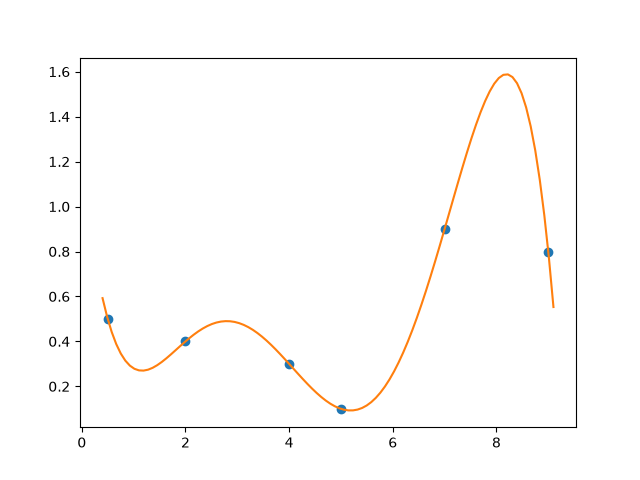

In [143]:
%matplotlib widget
import matplotlib.pyplot as plt

# Invent some raw data 
x=np.array([0.5,2.0,4.0,5.0,7.0,9.0])
y=np.array([0.5,0.4,0.3,0.1,0.9,0.8])

# BarycentricInterpolator returns an object that can be called like a function
# (scipy.interpolate.lagrange, used in older examples, is deprecated)
lp = sitp.BarycentricInterpolator(x, y)

xx= np.linspace(0.4, 9.1, 100)
fig = plt.figure()
plt.plot(x,y, "o", xx, lp(xx))
plt.show()

Fit a polynomial of arbitrary degree to a data set. Notice that the object returned is not a function this time and needs to be transformed into a function.

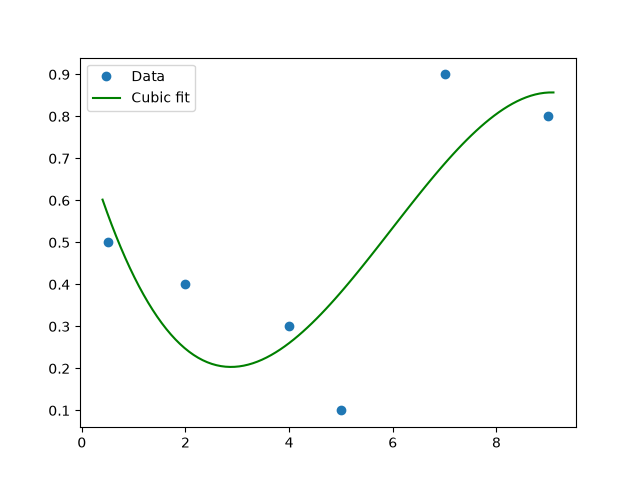

In [144]:
poly_coeffs=np.polyfit(x, y, 3)
p3 = np.poly1d(poly_coeffs)
fig = plt.figure()
plt.plot(x, y, "o", label="Data")
plt.plot(xx, p3(xx), 'g', label='Cubic fit')
plt.legend()
plt.show()

### Optimisation

`scipy.optimize` provides a very wide range of optimisation methods: Newton-like minimization algorithms, least square methods, root finding... 

NB. Examples below are inspired from the official documentation. Interesting examples require setting up complex problems and exceed the scope of this module. You will however encounter more involved optimisation problems later in the course!

In [145]:
import scipy.optimize as sopt

Let's find the minimum of a simple 1D function: <br>

$$ f(x) = -e^{-(x-0.2)^2} $$

In [146]:
## Lets define the function and then pass it to the scipy optimize routine

def f(x):
    return -np.exp(-(x - 0.2)**2)

result = sopt.minimize_scalar(f)

x_min = result.x
print(x_min)

0.19999999453196227


And now a more complex 2D one:

$$ f(x,y)=\frac{1}{2}(1-x)^{2}+(y-x^{2})^{2} $$


In [147]:
def f(x):   # rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2

def jacobian(x):
    return np.array((-2*.5*(1 - x[0]) - 4*x[0]*(x[1] - x[0]**2), 2*(x[1] - x[0]**2)))

sopt.minimize(f, [2,-1], method="Newton-CG", jac=jacobian) 

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.5601357400786612e-15
       x: [ 1.000e+00  1.000e+00]
     nit: 10
     jac: [ 1.058e-07 -7.483e-08]
    nfev: 11
    njev: 33
    nhev: 0

### Special functions

`scipy.special` provides a certain number of useful mathematical functions: Airy functions, Bessel functions, elliptic integrals, gamma function, erf, binomial law, etc. <br>

Reference documentation: https://docs.scipy.org/doc/scipy/reference/special.html

## Plotting with Matplotlib

From the official [documentation](https://matplotlib.org/):
> Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python. Matplotlib makes easy things easy and hard things possible.

In this notebook, we are mostly focused on the [`matplotlib.pyplot`](https://matplotlib.org/stable/api/pyplot_summary.html) submodule. Matplotlib has two interfaces, and we use both: the implicit `pyplot` one (`plt.plot(...)`, which draws on the "current" figure and axes), for most of the simple examples, and the explicit, object-oriented one (`fig, ax = plt.subplots()`, then `ax.plot(...)`), which we use for subplots and which is recommended for anything more complex (see [Matplotlib Application Interfaces](https://matplotlib.org/stable/users/explain/figure/api_interfaces.html)).

### Importing Matplotlib

The most standard:
```
import matplotlib.pyplot as plt
```
Imports such as `from matplotlib.pyplot import *` should be avoided, this will pollute your `namespace`!

iPython magic can be used to display plots in the browser:
```
%matplotlib inline
```
or for fancier dynamic plots
```
%matplotlib widget
```
You can see what a magic command does by typing, e.g., `%matplotlib?`. Note that, in that case, you need to import `pyplot` **after** the magic command.

### Basic plots

Let's prepare some data:

In [148]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt

rng = np.random.default_rng()

x = np.linspace(0, 2*np.pi, 100)
y = np.sin(x)
z = np.sin(x+np.pi/2)

Plotting this data is as simple as:

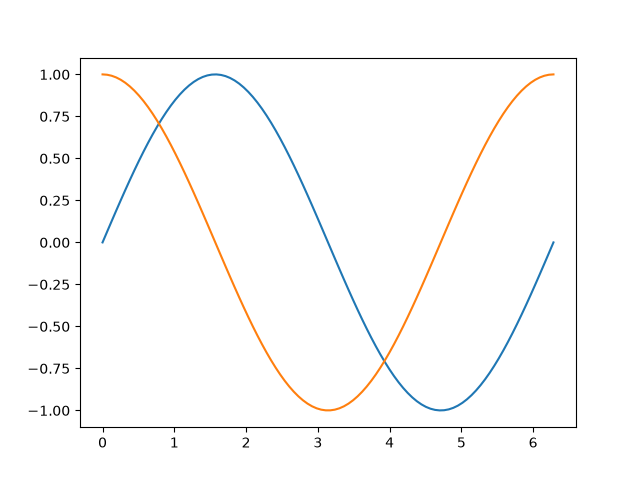

In [149]:
fig = plt.figure()

plt.plot(x, y)
plt.plot(x, z)
plt.show()

or

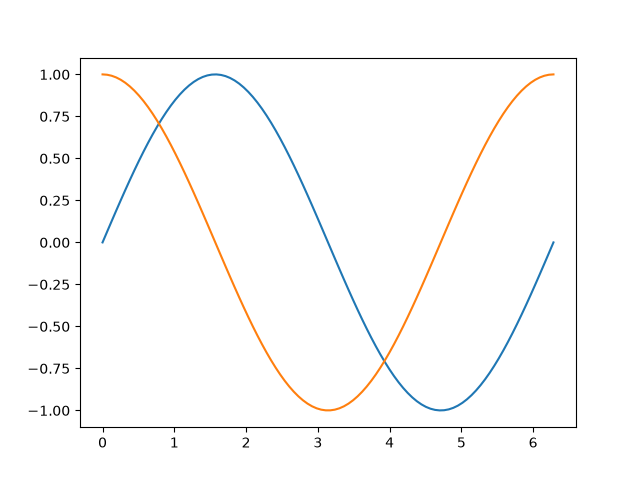

In [150]:
fig = plt.figure()

plt.plot(x,y, x, z)
plt.show()

We can specify axes limits and titles, and a global plot title:

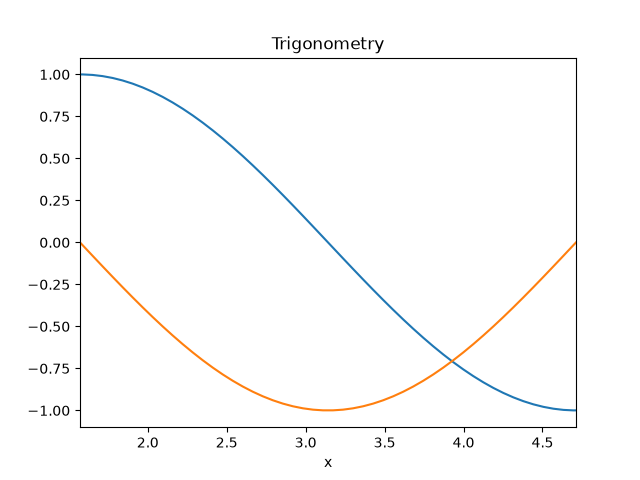

In [151]:
fig = plt.figure()

plt.xlim((x.max()*0.25, x.max()*0.75))
plt.xlabel("x")
plt.title("Trigonometry")
plt.plot(x,y, x, z)
plt.show()

as well as legends:

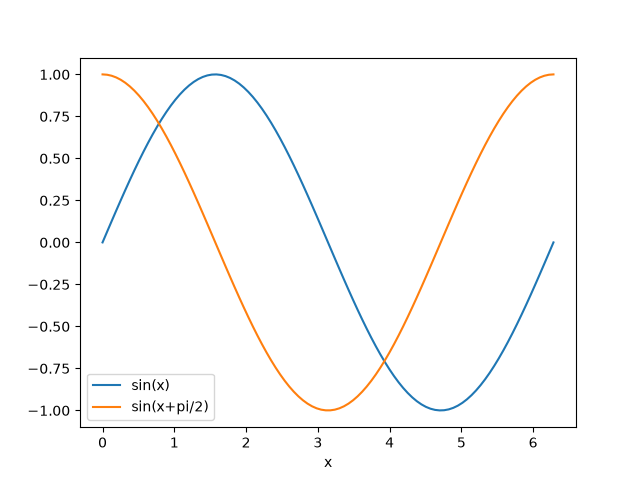

In [152]:
fig = plt.figure()

plt.xlabel("x")
plt.plot(x,y, x, z)
plt.legend(("sin(x)", "sin(x+pi/2)"))
plt.show()

### Line style

Each curve of the plot can be decorated individually:

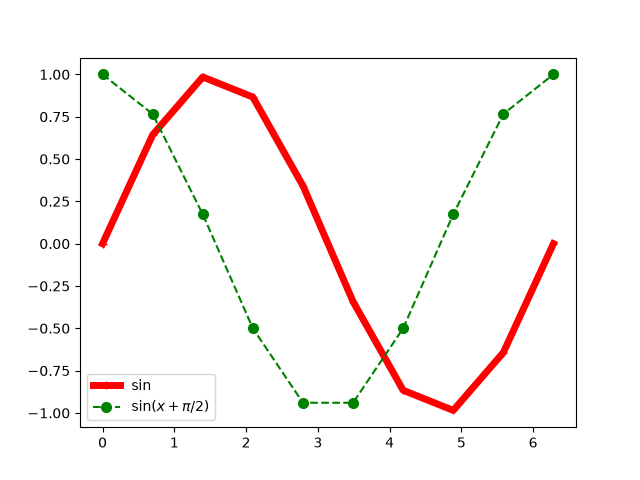

In [153]:
x1 = np.linspace(0, 2*np.pi, 10)
y1 = np.sin(x1)
z1 = np.sin(x1+np.pi/2)

fig = plt.figure()

plt.plot(x1, y1, '+-r', label="sin", linewidth=5.0)
plt.plot(x1, z1, 'o--g', label=r"$\sin(x+\pi/2)$", markersize=7.0)
plt.legend()
plt.show()

Plots can even be annotated !

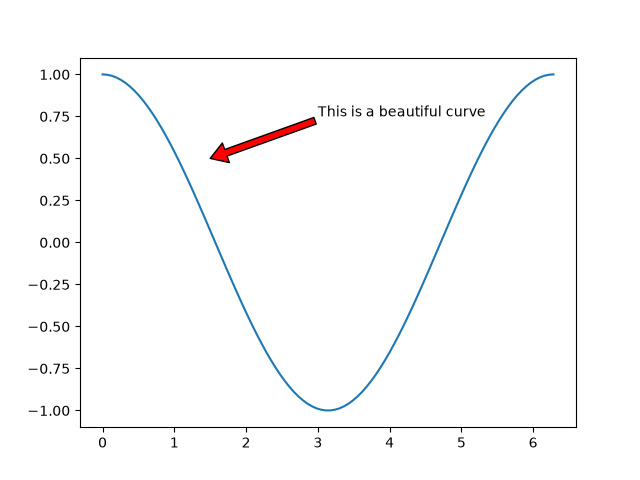

In [154]:
fig = plt.figure()

plt.plot(x, z)
atext = 'This is a beautiful curve'
arrowtiploc = (1.5, 0.5)
textloc=(3, 0.75)
plt.annotate(atext, xy=arrowtiploc, xytext=textloc,
            arrowprops=dict(width=5,headwidth=15,
            facecolor='red'))
plt.show()

### Histograms

Many other forms of plots can be made, such as histograms. For a more complete list see [here](https://matplotlib.org/stable/gallery/index.html).

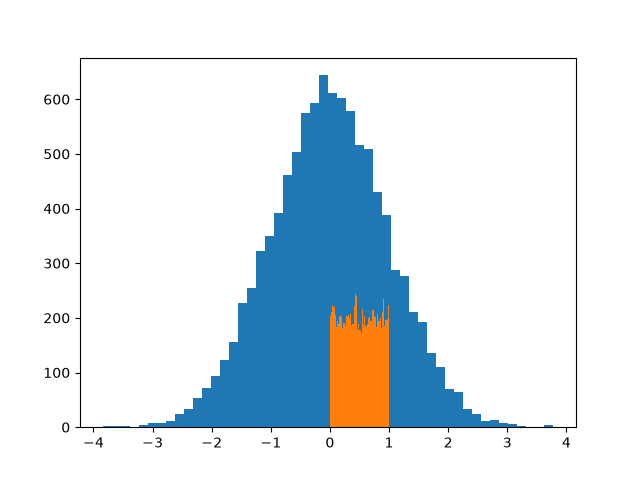

In [155]:
fig = plt.figure()

#10,000 Uniform random numbers
x2 = rng.random(10000)
#10,000 Normally distributed random numbers
y2 = rng.standard_normal(10000)
#Plot both on a histogram with 50 bins
plt.hist(y2, 50)
plt.hist(x2, 50)
plt.show() #Or plt.savefig("out.png")

### Saving images

Sometimes, you might want to save images for a report or a presentation. Instead of taking a screenshot of the plot, you can save it to a file. The file format is determined by the filename extension you supply. The following common  formats are supported: `.png`, `.jpg`, `.pdf` and `.ps`. There are other options to control the size and resolution of the output.

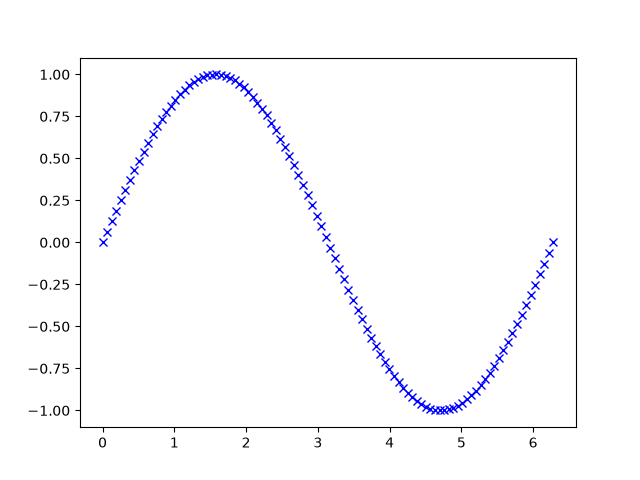

In [156]:
fig = plt.figure()

plt.plot(x, y, 'bx')
plt.savefig("sin.png", dpi=200)
plt.show()

### Subplots

Sometimes, you will want to group several plots in a single figure. Matplotlib provides an flexible way of managing subplots.
```
    (fig, axes) = plt.subplots(nrows, ncols)
```
`subplots()` returns a tuple with a reference to the figure (`fig`) and an array of references to each subplot axes (`axes`)

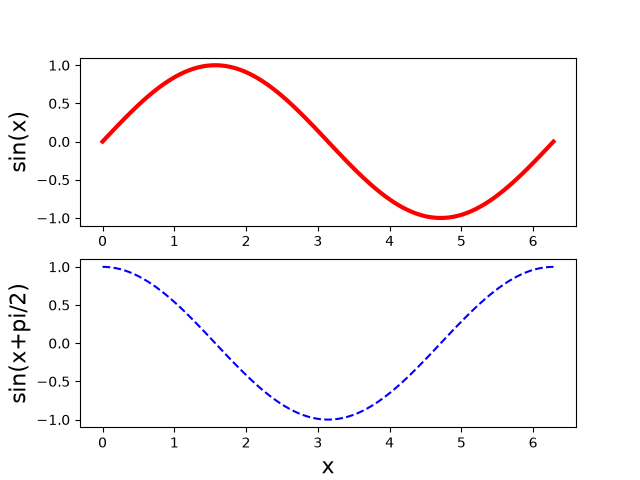

In [157]:
fig, axes = plt.subplots(2,1)
axes[0].plot(x, y, lw=3., c='r')
axes[1].plot(x, z, '--b')
axes[1].set_xlabel("x", fontsize=16)
axes[0].set_ylabel("sin(x)", fontsize=16)
axes[1].set_ylabel("sin(x+pi/2)", fontsize=16)
plt.show()

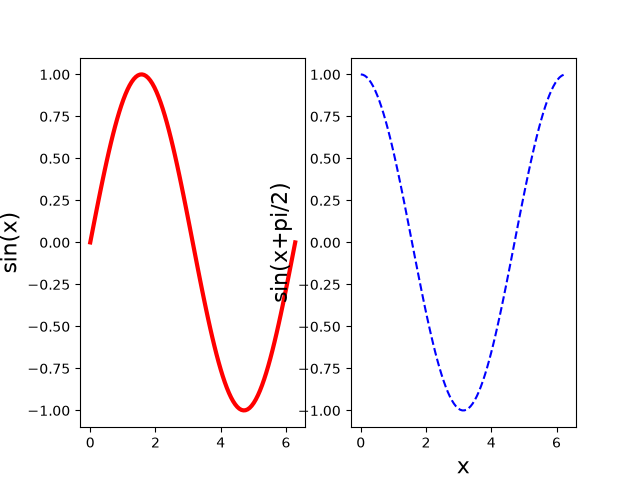

In [159]:
fig, axes = plt.subplots(1,2)
axes[0].plot(x, y, lw=3., c='r')
axes[1].plot(x, z, '--b')
axes[1].set_xlabel("x", fontsize=16)
axes[0].set_ylabel("sin(x)", fontsize=16)
axes[1].set_ylabel("sin(x+pi/2)", fontsize=16)
plt.show()

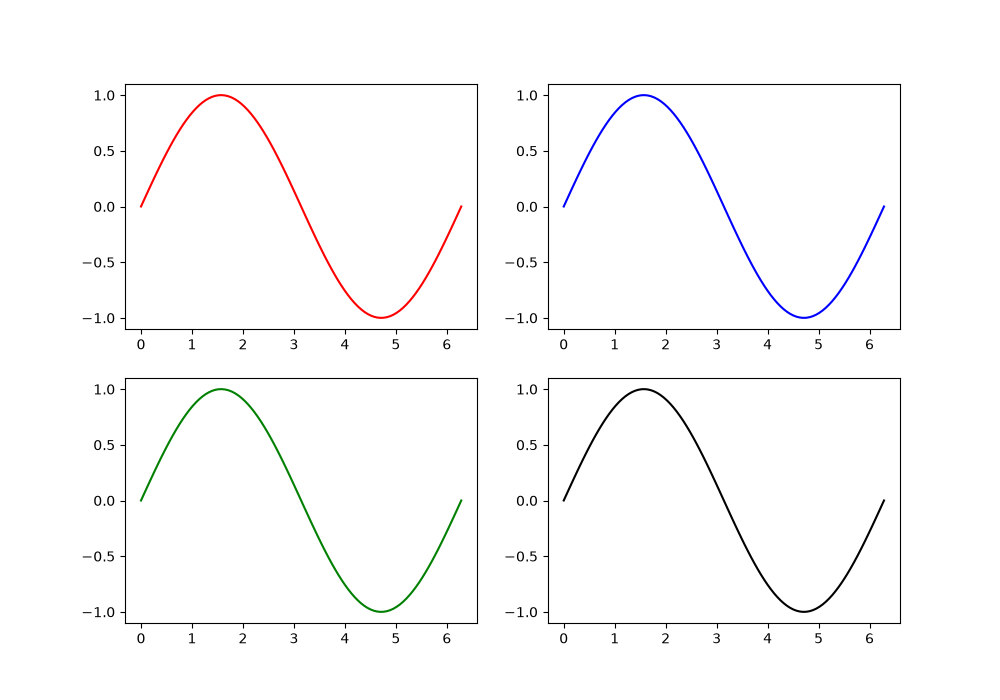

In [160]:
(fig, axes) = plt.subplots(2, 2, figsize=(10,7))
axes[0,0].plot(x, y, 'r')
axes[0,1].plot(x, y, 'b')
axes[1,0].plot(x, y, 'g')
axes[1,1].plot(x, y, 'k')
plt.show()

Alternatively, you can select a subplot and make it the "current subplot"

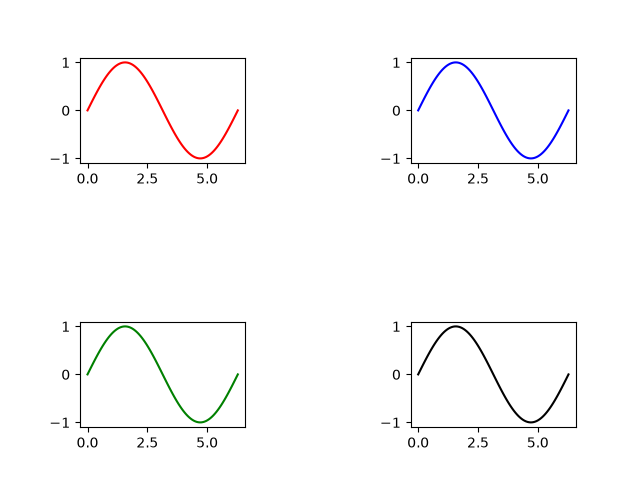

In [161]:
(fig, axes) = plt.subplots(2, 2)
plt.subplots_adjust(wspace = 1., hspace=1.5)

plt.sca(axes[0,0])
plt.plot(x, y, 'r')
plt.sca(axes[0,1])
plt.plot(x, y, 'b')
plt.sca(axes[1,0])
plt.plot(x, y, 'g')
plt.sca(axes[1,1])
plt.plot(x, y, 'k')
plt.show()

For more complex subplot layouts `plt.subplot2grid` can be used. It maps the figure to a grid, and you can define subplots spanning across several cells of the grid. It takes 4 arguments:
```
subplot2grid(shape,
             location,
             rowspan = 1,
             colspan = 1)
```
`shape` is the shape of the grid (number of cells), it needs to be the same for each call of the function within one figure. `location` is the location of the top-left corner of the subplot. `rowspan` and `colspan` are the numbers of grid rows and columns the subplot spans (its height and width).

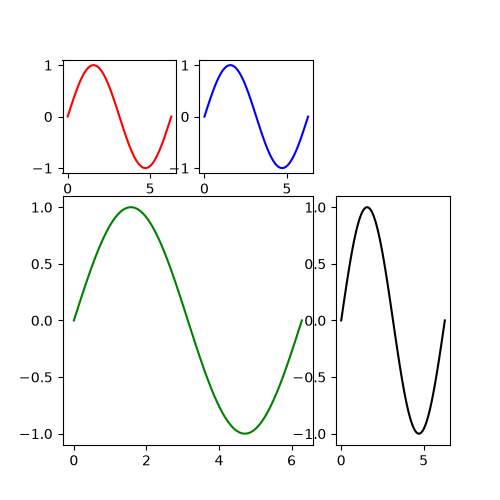

In [162]:
fig = plt.figure()
fig.set_figheight(5)
fig.set_figwidth(5)

ax1 = plt.subplot2grid((3, 3), (0, 0))
ax2 = plt.subplot2grid((3, 3), (0, 1), colspan=1)
ax3 = plt.subplot2grid((3, 3), (1, 0), colspan=2, rowspan=2)
ax4 = plt.subplot2grid((3, 3), (1, 2), rowspan=2)
# what happens if you uncomment the following line? 
#ax5 = plt.subplot2grid((3, 3), (1, 1), colspan=1, rowspan=1)
ax1.plot(x, y, 'r')
ax2.plot(x, y, 'b')
ax3.plot(x, y, 'g') 
ax4.plot(x, y, 'k')
plt.show()

### 2D Plots

There are several ways to represent multidimensional data. One can choose to represent the data contained in a 2D domain (a matrix) with colors (in a 2D plot), or with surfaces (in a 3D plot).

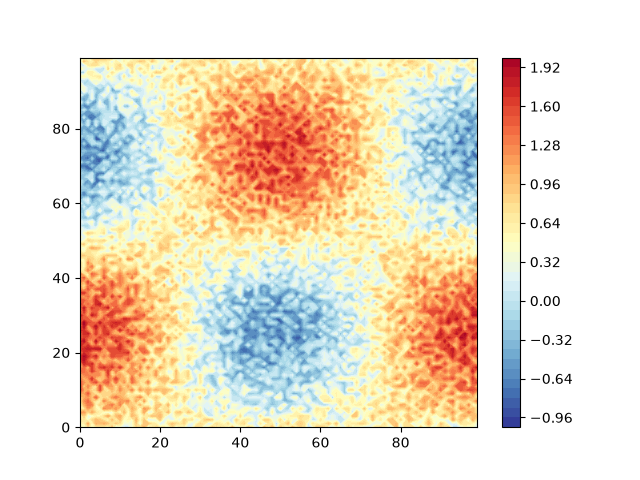

In [163]:
fig = plt.figure()

N = 100
x = np.linspace(0,2*np.pi,N)
y = np.sin(x); z = np.cos(x)
#Create 2D field from outer product of previous 1D functions
noise = rng.random(N**2)
u = np.outer(y,z) + noise.reshape(N,N)
plt.contourf(u, 40, cmap=plt.cm.RdYlBu_r)
plt.colorbar()
plt.show()

### <span style="color:blue">Exercise 2.15</span>

Consider the following functions defined on the 2D square domain $\Omega = [0,1]^2$:

$$ a(x) = \tanh\left(50\sin\left(\frac{25}{2}\pi x\right)\right)$$

and

$$ f(\mathbf{x}) = a(a(|\mathbf{x}-\mathbf{x}_0|)) + a(a(|\mathbf{x}-\mathbf{x}_1|)) $$

for any $\mathbf{x} \in \Omega$, with $\mathbf{x}_0=(0,0)$ and $\mathbf{x}_1=(1,1)$

Plot $f$ on $\Omega$. You may want to use `numpy.meshgrid`.

Call the function $f(\mathbf{x})$ `func_f(x,y)` and have its input be 1D arrays for the sample x and y-coordinates. <br>
The function $a(x)$ should be called `func_a(x)`. <br>

<>:29: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:29: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_294789/3122041192.py:29: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  fig.colorbar(cp, ax=ax, label='$f(\mathbf{x})$')
/tmp/ipykernel_294789/3122041192.py:31: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mea

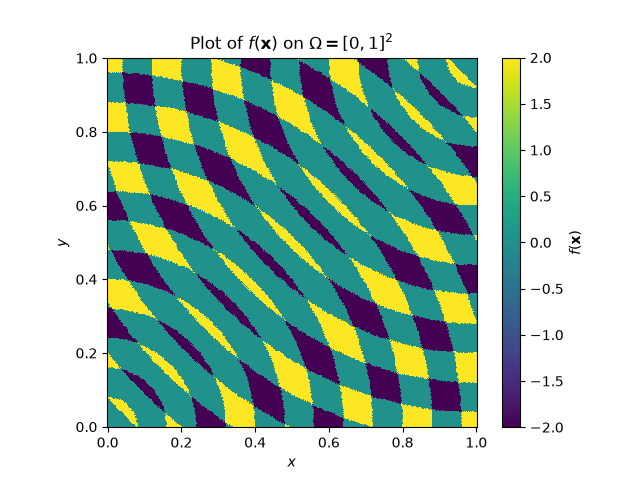

In [169]:
fig = plt.figure()
## Solution...

def func_a(x):
    return np.tanh(50 * np.sin((25 / 2) * np.pi * x))

def func_f(x, y):
    # Create a 2D grid from the 1D sample arrays
    X, Y = np.meshgrid(x, y)
    
    # Compute the Euclidean distances from x0=(0,0) and x1=(1,1)
    norm_x0 = np.sqrt(X**2 + Y**2)
    norm_x1 = np.sqrt((X - 1)**2 + (Y - 1)**2)
    
    # Calculate the composition f(x)
    return func_a(func_a(norm_x0)) + func_a(func_a(norm_x1))

# 1. Define 1D sample coordinate arrays for the domain [0, 1]
# Using 400 points ensures the sharp wave transitions are captured clearly
x_coords = np.linspace(0, 1, 400)
y_coords = np.linspace(0, 1, 400)

# 2. Evaluate the function across the coordinates
Z = func_f(x_coords, y_coords)

# 3. Create the pseudocolor plot on the existing figure
ax = fig.add_subplot(111)
cp = ax.pcolormesh(x_coords, y_coords, Z, cmap='viridis', shading='auto')
fig.colorbar(cp, ax=ax, label='$f(\mathbf{x})$')

ax.set_title('Plot of $f(\mathbf{x})$ on $\Omega = [0, 1]^2$')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_aspect('equal')

In [170]:
# Check your answer by running this cell (don't change it). If an assertion fails, its message says what to look at.
assert np.isclose(func_a(0.0), 0.0) and np.isclose(func_a(0.04), np.tanh(50.0)), "func_a does not match a(x)"
xs = np.linspace(0, 1, 101)
F = func_f(xs, xs)
assert np.shape(F) == (101, 101), "func_f(x, y) should return a 2D array: one value for each point of the grid"
assert np.isclose(F[0, 0], func_a(func_a(np.sqrt(2.0)))), "func_f is not right at the corner (0, 0)"
print("Correct.")

Correct.


### 3D Plots

A wide variety of options are available for 3D plots, they are usually contained in specific submodules.

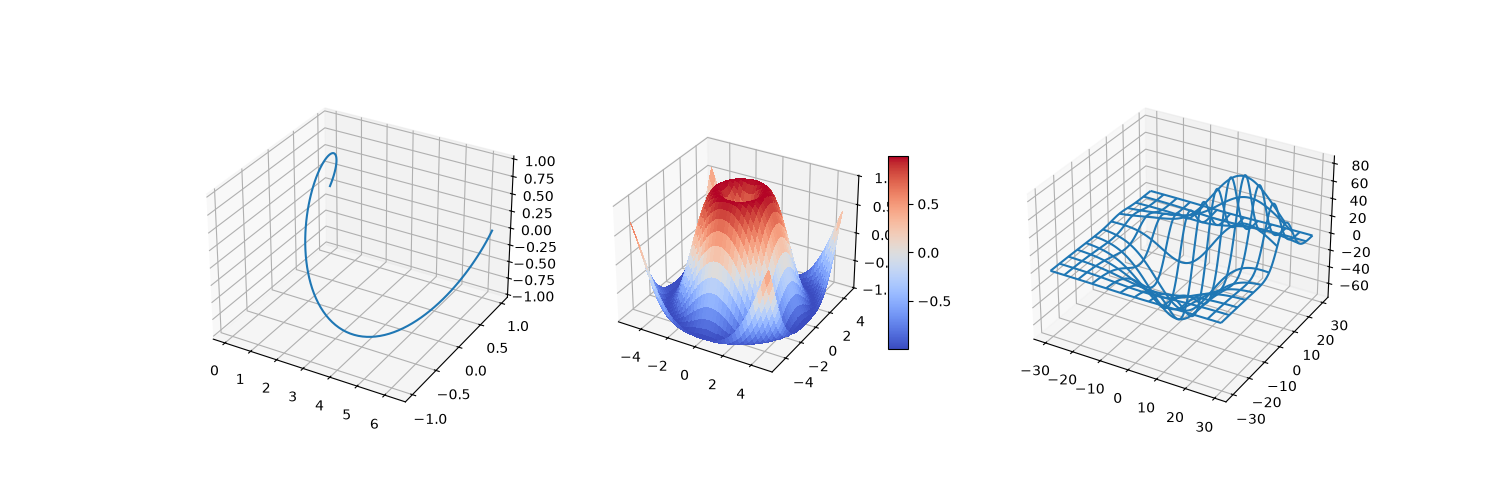

In [171]:
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.axes3d import get_test_data

fig = plt.figure()
fig.set_figheight(5)
fig.set_figwidth(15)

ax = fig.add_subplot(1,3,1, projection='3d')

# plot a curve
x = np.linspace(0.,2*np.pi,100)
ax.plot(x, np.cos(x), np.sin(x))

ax = fig.add_subplot(1, 3, 2, projection='3d')

# plot a 3D surface
X = np.arange(-5, 5, 0.25)
Y = np.arange(-5, 5, 0.25)
X, Y = np.meshgrid(X, Y)
R = np.sqrt(X**2 + Y**2)
Z = np.sin(R)
surf = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, cmap=plt.cm.coolwarm,
                       linewidth=0, antialiased=False)
ax.set_zlim(-1.01, 1.01)
fig.colorbar(surf, shrink=0.5, aspect=10)

ax = fig.add_subplot(1, 3, 3, projection='3d')

# plot a 3D wireframe like in the example mplot3d/wire3d_demo
X, Y, Z = get_test_data(0.05)
ax.plot_wireframe(X, Y, Z, rstride=10, cstride=10)

plt.show()

### Animations

Animations (*i.e.* series of images) can be created with matplotlib. However, exercise some restraint as they can require significant resources.

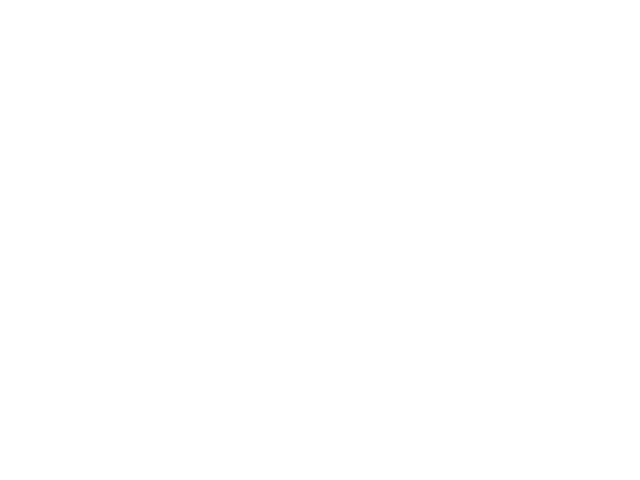

In [172]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation

fig = plt.figure()

def get_field(a, N = 100):
    x = a*np.linspace(0,2*np.pi,N)
    y = np.sin(x); z = np.cos(x)
    out =  np.outer(y,z)
    plt.contourf(out, 40, cmap=plt.cm.RdYlBu_r)

        
ani= matplotlib.animation.FuncAnimation(plt.gcf(), get_field, frames=range(0,10),
                                       interval=500, repeat=False)
plt.show()

ERROR:tornado.application:Exception in callback <bound method TimerBase._on_timer of <matplotlib.backends.backend_webagg_core.TimerTornado object at 0x79e0d0f6d2b0>>
Traceback (most recent call last):
  File "/home/uu26/miniconda3/envs/mpm2026/lib/python3.14/site-packages/tornado/ioloop.py", line 945, in _run
    val = self.callback()
  File "/home/uu26/miniconda3/envs/mpm2026/lib/python3.14/site-packages/matplotlib/backend_bases.py", line 1165, in _on_timer
    ret = func(*args, **kwargs)
  File "/home/uu26/miniconda3/envs/mpm2026/lib/python3.14/site-packages/matplotlib/animation.py", line 1470, in _step
    still_going = super()._step(*args)
  File "/home/uu26/miniconda3/envs/mpm2026/lib/python3.14/site-packages/matplotlib/animation.py", line 1158, in _step
    self._draw_next_frame(framedata, self._blit)
    ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/uu26/miniconda3/envs/mpm2026/lib/python3.14/site-packages/matplotlib/animation.py", line 1177, in _draw_next_frame
   

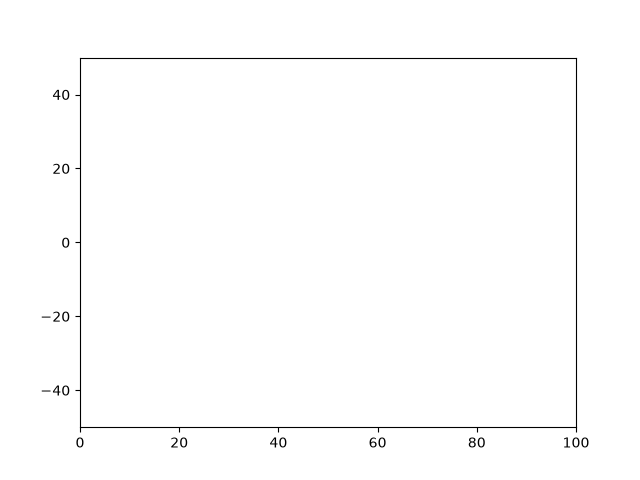

In [173]:
import random

ysample = random.sample(range(-50, 50), 100)

xdata = []
ydata = []

fig = plt.figure()

axes = plt.gca()
axes.set_xlim(0, 100)
axes.set_ylim(-50, +50)
line, = axes.plot(xdata, ydata, 'r-')

def update(i):
    xdata.append(i)
    ydata.append(ysample[i])
    line.set_xdata(xdata)
    line.set_ydata(ydata)

ani= matplotlib.animation.FuncAnimation(plt.gcf(), update, frames=100,
                                       interval=100, repeat=False)

plt.show()

Movies can be generated by saving images then calling an external program like `ffmpeg`, or by saving the animation directly with, e.g., `ani.save("movie.mp4")`, which also uses `ffmpeg` under the hood.

### Widgets

Matplotlib provides widgets, that allow you to create dynamic plots with sliders and things like that.

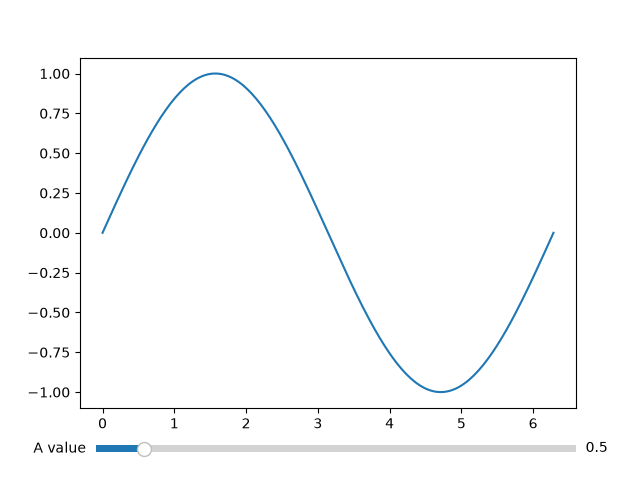

In [175]:
import matplotlib.widgets as mw

fig = plt.figure()

#Setup initial plot of sine function
x = np.linspace(0, 2*np.pi, 200)
l, = plt.plot(x, np.sin(x))
#Adjust figure to make room for slider
plt.subplots_adjust(bottom=0.15)
axslide = plt.axes([0.15, 0.05, 0.75, 0.03]) 
s = mw.Slider(axslide, 'A value', 0., 5.)

#Define function
def update(A):
    l.set_ydata(np.sin(A*x))
    plt.draw()
#Bind update function to change in slider
s.on_changed(update)
plt.show()

## Summary

  * `NumPy`: defines `ndarray`s, which are an efficient data structure for large vectors, matrices and tensors, and provides many functions to manipulate them.
  * `SciPy`: defines a lot of user-friendly routines useful for scientific codes.
  * Both utilize efficient low level code under the hood, and hence will generally be much faster than re-implementing the same functions yourself in pure Python.
  * Vectorization !
  * `Matplotlib`: allows you to draw and save plots, from the simplest 2D line plot to complicated 3D plots.
  * Refer to the online documentation for a complete list of features: https://docs.scipy.org/doc/

## Self-check quiz

This lecture has a short multiple-choice [self-check quiz](quiz.ipynb) on its main points: open the notebook and click an option under each question. This lecture's exercises run alongside the material, so take the quiz once you have worked through it, and before you start the supplemental exercises or any part of the coursework that relies on it. The answers, with explanations, will be released later so that you can check your own. The quiz is not assessed, but it is good preparation for the multiple-choice part of the consolidation test.
